In [1]:
import pandas as pd

In [2]:
data=pd.read_csv('New Microsoft Excel Worksheet.csv',encoding='utf-8')


C:\Users\dell\AppData\Local\Temp\ipykernel_25372\3950237199.py:1: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10) have mixed types. Specify dtype option on import or set low_memory=False.
  data=pd.read_csv('New Microsoft Excel Worksheet.csv',encoding='utf-8')


In [3]:
pd.set_option("display.max_rows",50)
pd.set_option("display.min_rows",50)


In [4]:
data['arabic_name2'].nunique()

6171

In [36]:
name_counts = data['arabic_name2'].value_counts()

print(name_counts)

arabic_name2
محمد         73668
احمد         48075
يوسف         31967
مريم         29421
ملك          26303
عبدالرحمن    20430
عمر          18220
منة          17094
شهد          16263
حبيبة        16158
محمود        15945
جنى          15204
سلمى         13426
زياد         12189
مصطفى        12041
ندى          10995
بسملة        10924
فاطمة        10901
عبدالله      10244
حنين          9859
اية           8881
سارة          8830
رحمة          8656
ياسمين        7790
نور           7790
             ...  
شيشوى            1
تيودور           1
أبتهال           1
مادولين          1
صموائيل          1
فوقية            1
سيمه             1
وردشان           1
فنار             1
فينوس            1
اَدم             1
بنودى            1
مطر              1
هلول             1
صلى              1
بسميه            1
ستي              1
\tادم            1
ناديره           1
ميراف            1
ضاوى             1
منطونى           1
بياندا           1
سيرميان          1
أيرين            1
Name: count, Lengt

In [5]:
df_counts = data['arabic_name2'].value_counts().reset_index()
df_counts.columns = ['Name', 'Repetitions']
df_counts.head(50)

,Name,Repetitions
0,محمد,73668
1,احمد,48075
2,يوسف,31967
3,مريم,29421
4,ملك,26303
5,عبدالرحمن,20430
6,عمر,18220
7,منة,17094
8,شهد,16263
9,حبيبة,16158


In [37]:
Unique_Names = df_counts[df_counts["Repetitions"] == 1].copy()
Unique_Names

,Name,Repetitions
3532,رونايدا,1
3533,الاسامه,1
3534,فطومه,1
3535,نورالحسين,1
3536,معزبالله,1
3537,رقيقه,1
3538,ابوالعزم,1
3539,هندا,1
3540,احمدمنصورعبدالغني,1
3541,نيفادا,1


In [38]:
import matplotlib.pyplot as plt
from bidi.algorithm import get_display

def arabic_text(text):
    reshaped = arabic_reshaper.reshape(text)
    return get_display(reshaped)

plt.rcParams['font.family'] = 'Arial'


In [28]:
import sys
import subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "arabic_reshaper", "python-bidi"])

0

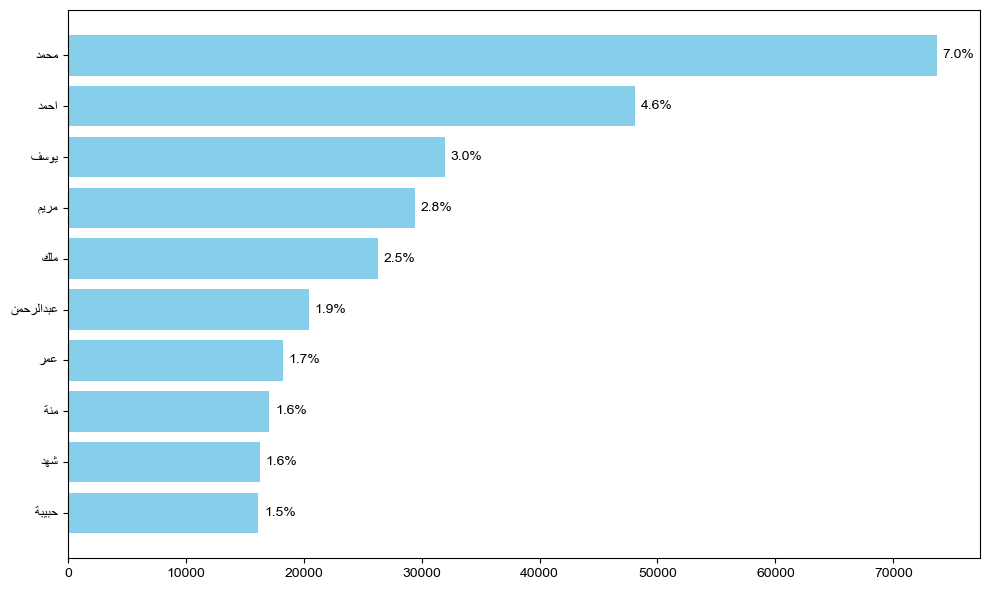

In [39]:

import arabic_reshaper
from bidi.algorithm import get_display

# Function to fix Arabic text
def fix_arabic(text):
    reshaped = arabic_reshaper.reshape(str(text))
    return get_display(reshaped)

# Get top 10
top10 = data['arabic_name2'].value_counts().head(10).reset_index()
top10.columns = ['Name', 'Count']

# Calculate percentage
top10['Percentage'] = (top10['Count'] / len(data)) * 100

# Fix Arabic names
top10['Name_fixed'] = top10['Name'].apply(fix_arabic)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top10['Name_fixed'][::-1],
    top10['Count'][::-1],
    color='skyblue'
)

# Add percentages
for bar, pct in zip(bars, top10['Percentage'][::-1]):
    width = bar.get_width()
    ax.text(
        width + 500,
        bar.get_y() + bar.get_height() / 2,
        f'{pct:.1f}%',
        va='center'
    )

plt.tight_layout()
plt.show()

In [57]:
df_counts.head(30)

,Name,Repetitions
0,محمد,73668
1,احمد,48075
2,يوسف,31967
3,مريم,29421
4,ملك,26303
5,عمر,18220
6,منة,17094
7,شهد,16263
8,حبيبة,16158
9,محمود,15945


In [30]:
male_names = ['محمد', 'احمد', 'محمود', 'عمر', 'علي',
              'عبدالرحمن', 'زياد', 'يوسف', 'مصطفى', 'عبدالله']

female_names = ['مريم', 'فاطمة', 'ندى', 'منة', 'شهد',
                'بسملة', 'ملك', 'جنى', 'سلمى', 'حبيبة']

In [41]:
male_counts = data[data['arabic_name2'].isin(male_names)]['arabic_name2'].value_counts()

female_counts = data[data['arabic_name2'].isin(female_names)]['arabic_name2'].value_counts()

In [42]:
top_names = pd.concat([male_counts, female_counts])

In [43]:
top_names = top_names.sort_values(ascending=True)

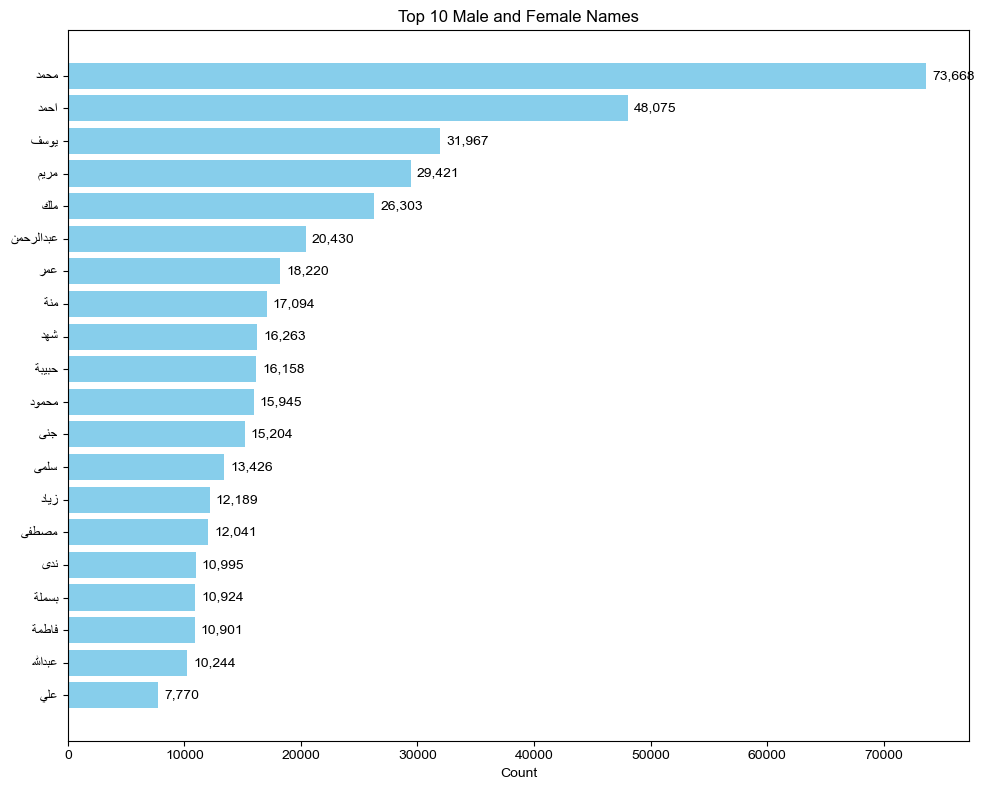

In [44]:
names_fixed = [
    get_display(arabic_reshaper.reshape(name))
    for name in top_names.index
]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(
    names_fixed,
    top_names.values,
    color='skyblue'
)

# Add values
for bar in bars:
    ax.text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height() / 2,
        f'{int(bar.get_width()):,}',
        va='center'
    )

ax.set_title('Top 10 Male and Female Names')
ax.set_xlabel('Count')

plt.tight_layout()
plt.show()

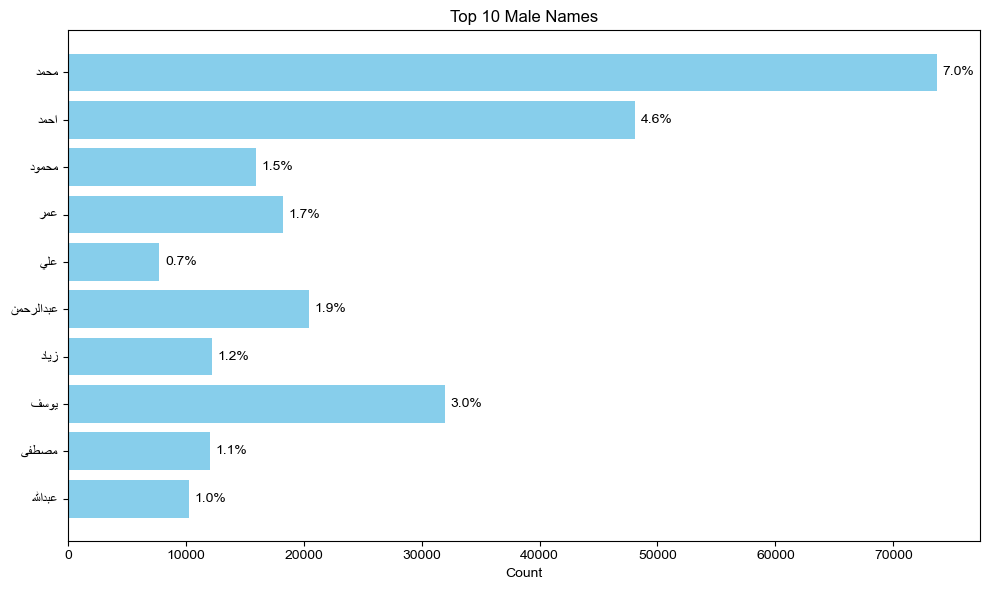

In [64]:
male_counts = (
    data[data['arabic_name2'].isin(male_names)]
    ['arabic_name2']
    .value_counts()
    .reindex(male_names)
    .dropna()
)

male_percentage = male_counts / len(data) * 100

male_names_fixed = male_counts.index.map(fix_arabic)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    male_names_fixed[::-1],
    male_counts.values[::-1],
    color='skyblue'
)

for bar, pct in zip(bars, male_percentage.values[::-1]):
    ax.text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height() / 2,
        f'{pct:.1f}%',
        va='center'
    )

ax.set_title('Top 10 Male Names')
ax.set_xlabel('Count')

plt.tight_layout()
plt.show()


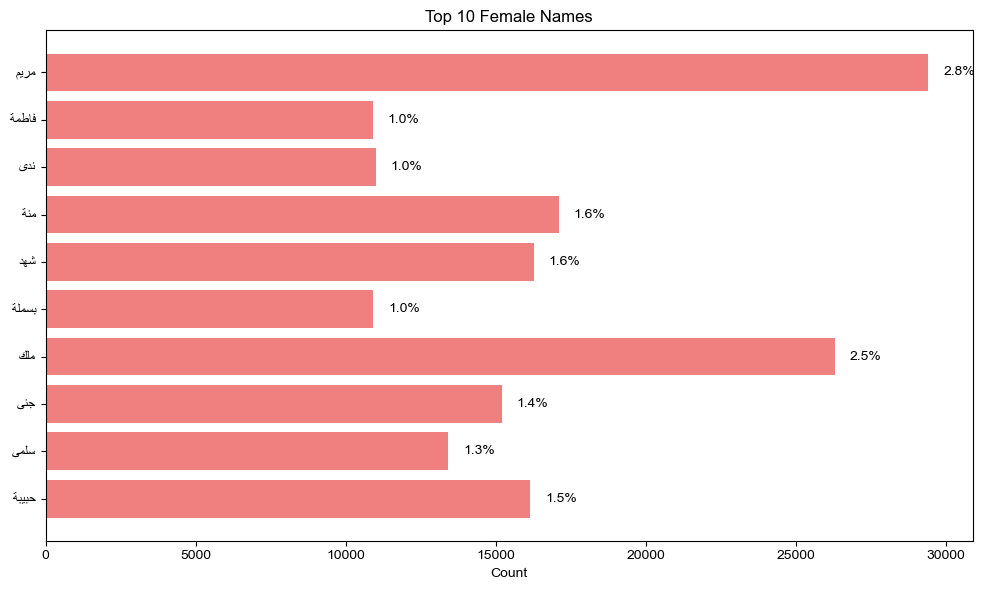

In [45]:

female_counts = (
    data[data['arabic_name2'].isin(female_names)]
    ['arabic_name2']
    .value_counts()
    .reindex(female_names)
    .dropna()
)

female_percentage = female_counts / len(data) * 100

female_names_fixed = female_counts.index.map(fix_arabic)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    female_names_fixed[::-1],
    female_counts.values[::-1],
    color='lightcoral'
)

for bar, pct in zip(bars, female_percentage.values[::-1]):
    ax.text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height() / 2,
        f'{pct:.1f}%',
        va='center'
    )

ax.set_title('Top 10 Female Names')
ax.set_xlabel('Count')

plt.tight_layout()
plt.show()

In [25]:
Unique_Names.to_excel("Unique Names.xlsx", index=False)

In [47]:
fathers_names = data['arabic_name3'].value_counts().reset_index()
fathers_names.columns = ['Name', 'Repetitions']
fathers_names.head(20)

,Name,Repetitions
0,محمد,146315
1,احمد,78465
2,محمود,33287
3,ابراهيم,19053
4,السيد,17902
5,اشرف,16751
6,مصطفى,16595
7,خالد,16282
8,ايمن,13766
9,على,12333


In [58]:
top_father_names=fathers_names.head(10)


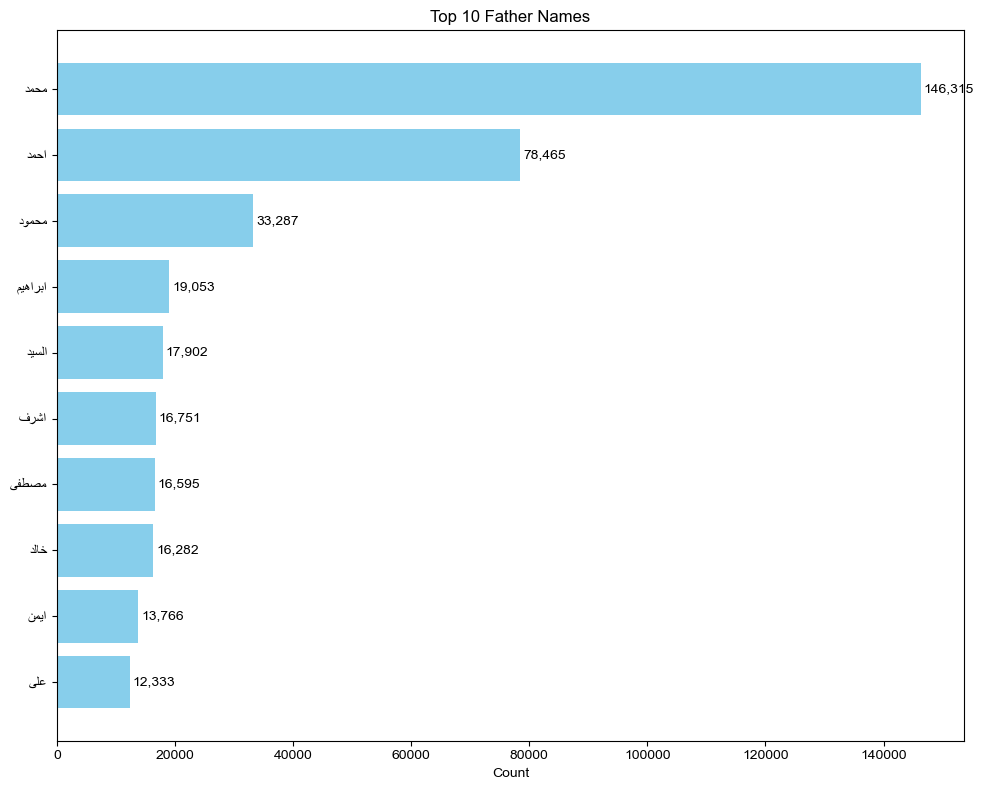

In [60]:
fathers_names_fixed = [
    get_display(arabic_reshaper.reshape(str(name)))
    for name in top_father_names['Name']
]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(
    fathers_names_fixed[::-1],
    top_father_names['Repetitions'].values[::-1],
    color='skyblue'
)

# Add values
for bar in bars:
    ax.text(
        bar.get_width() + 500,
        bar.get_y() + bar.get_height() / 2,
        f'{int(bar.get_width()):,}',
        va='center'
    )

ax.set_title('Top 10 Father Names')
ax.set_xlabel('Count')

plt.tight_layout()
plt.show()